# Level 2 · Task 1 — Logistic Regression for Binary Classification
**Codveda Technology — Machine Learning Internship**

**Goal:** predict whether a telecom customer will **churn** (cancel their subscription).

**Dataset:** Churn prediction data (BigML telecom churn) — already split by the provider into
`churn-bigml-80.csv` (2,666 customers, used for training) and `churn-bigml-20.csv` (667 customers, used for testing).

**Objectives covered**
1. Load and preprocess the dataset
2. Train a logistic regression model with scikit-learn
3. Interpret the model coefficients and the odds ratios
4. Evaluate with accuracy, precision, recall and the ROC curve

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve)

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load the data

In [2]:
train = pd.read_csv(DATA / "churn-bigml-80.csv")
test = pd.read_csv(DATA / "churn-bigml-20.csv")
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (2666, 20) | Test: (667, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
print("Missing values (train/test):", train.isna().sum().sum(), "/", test.isna().sum().sum())
print("Duplicate rows (train/test):", train.duplicated().sum(), "/", test.duplicated().sum())
print("\nChurn rate — train: {:.1%} | test: {:.1%}".format(train["Churn"].mean(), test["Churn"].mean()))
train.dtypes

Missing values (train/test): 0 / 0
Duplicate rows (train/test): 0 / 0

Churn rate — train: 14.6% | test: 14.2%


State                         str
Account length              int64
Area code                   int64
International plan            str
Voice mail plan               str
Number vmail messages       int64
Total day minutes         float64
Total day calls             int64
Total day charge          float64
Total eve minutes         float64
Total eve calls             int64
Total eve charge          float64
Total night minutes       float64
Total night calls           int64
Total night charge        float64
Total intl minutes        float64
Total intl calls            int64
Total intl charge         float64
Customer service calls      int64
Churn                        bool
dtype: object

The classes are **imbalanced** (~14.5 % churners). A model that always predicts "no churn" would already reach ~85 % accuracy,
so accuracy alone is misleading — precision, recall and ROC-AUC matter more here.

## 2. Exploratory look at churn drivers

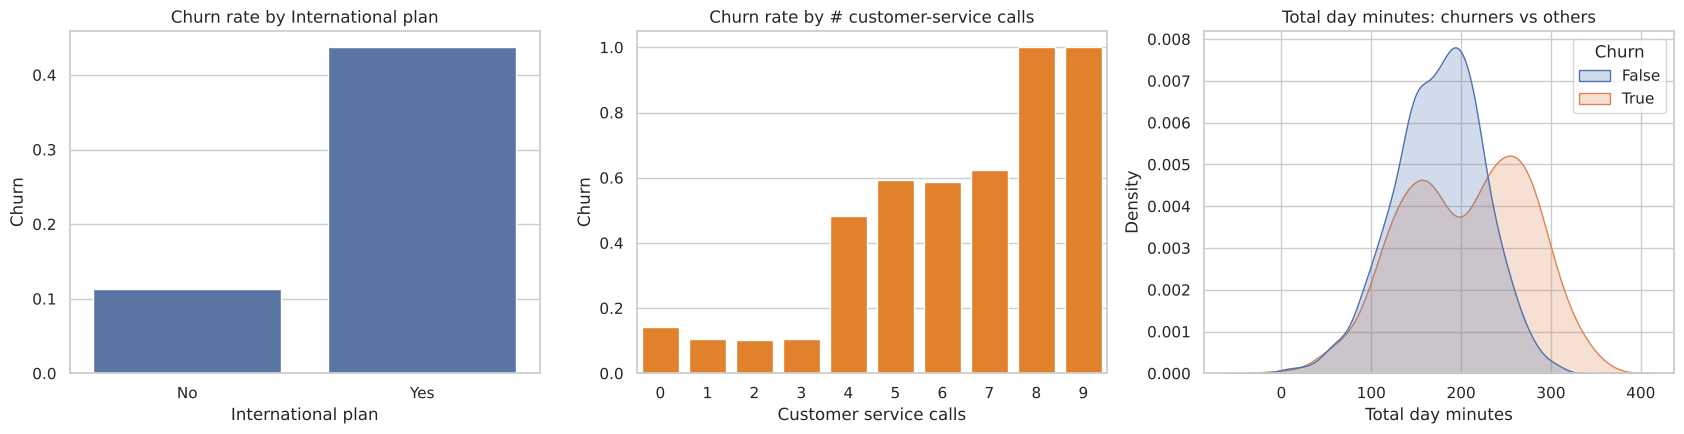

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(data=train, x="International plan", y="Churn", ax=axes[0], errorbar=None)
axes[0].set_title("Churn rate by International plan")
sns.barplot(data=train, x="Customer service calls", y="Churn", ax=axes[1], errorbar=None, color="tab:orange")
axes[1].set_title("Churn rate by # customer-service calls")
sns.kdeplot(data=train, x="Total day minutes", hue="Churn", common_norm=False, fill=True, ax=axes[2])
axes[2].set_title("Total day minutes: churners vs others")
plt.tight_layout(); plt.savefig(IMG / "eda.png", dpi=120); plt.show()

In [5]:
charge_cols = [c for c in train.columns if "charge" in c]
for c in charge_cols:
    m = c.replace("charge", "minutes")
    print(f"corr({m}, {c}) = {train[m].corr(train[c]):.4f}")

corr(Total day minutes, Total day charge) = 1.0000
corr(Total eve minutes, Total eve charge) = 1.0000
corr(Total night minutes, Total night charge) = 1.0000
corr(Total intl minutes, Total intl charge) = 1.0000


## 3. Preprocessing
* **Charges are a fixed price × minutes** (correlation = 1.0). Keeping both would make the coefficients unstable and impossible
  to interpret (perfect multicollinearity) → drop the 4 `charge` columns.
* `International plan`, `Voice mail plan` (Yes/No) and `Churn` (True/False) → binary 0/1.
* `State` (51 values) and `Area code` (3 values) are categorical → one-hot encoding.
* Numeric features → standardization, so coefficients are comparable.

In [6]:
def prepare(df):
    df = df.drop(columns=charge_cols).copy()
    df["International plan"] = (df["International plan"] == "Yes").astype(int)
    df["Voice mail plan"] = (df["Voice mail plan"] == "Yes").astype(int)
    df["Area code"] = df["Area code"].astype(str)
    df["Churn"] = df["Churn"].astype(int)
    return df

train_p, test_p = prepare(train), prepare(test)
X_train, y_train = train_p.drop(columns="Churn"), train_p["Churn"]
X_test, y_test = test_p.drop(columns="Churn"), test_p["Churn"]

categorical = ["State", "Area code"]
binary = ["International plan", "Voice mail plan"]
numeric = [c for c in X_train.columns if c not in categorical + binary]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("bin", "passthrough", binary),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
])
print("Numeric:", numeric)

Numeric: ['Account length', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total eve minutes', 'Total eve calls', 'Total night minutes', 'Total night calls', 'Total intl minutes', 'Total intl calls', 'Customer service calls']


## 4. Train logistic regression
Two versions are compared:
* **Standard** — every sample has equal weight.
* **Balanced** (`class_weight="balanced"`) — churners get more weight, so the model is pushed to find more of them (higher recall).

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
}
fitted, rows = {}, []
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)]).fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "CV ROC-AUC (train)": cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
metrics = pd.DataFrame(rows).set_index("Model").round(3)
metrics

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.806,0.855,0.477,0.221,0.302,0.814
Logistic Regression (balanced),0.804,0.774,0.361,0.768,0.492,0.819


In [8]:
for name, pipe in fitted.items():
    print("=" * 20, name, "=" * 20)
    print(classification_report(y_test, pipe.predict(X_test), target_names=["Stay", "Churn"], digits=3))

==================== Logistic Regression ====================
              precision    recall  f1-score   support

        Stay      0.881     0.960     0.919       572
       Churn      0.477     0.221     0.302        95

    accuracy                          0.855       667
   macro avg      0.679     0.590     0.610       667
weighted avg      0.824     0.855     0.831       667

==================== Logistic Regression (balanced) ====================
              precision    recall  f1-score   support

        Stay      0.953     0.774     0.854       572
       Churn      0.361     0.768     0.492        95

    accuracy                          0.774       667
   macro avg      0.657     0.771     0.673       667
weighted avg      0.868     0.774     0.803       667



## 5. Evaluation plots — confusion matrices and ROC curve

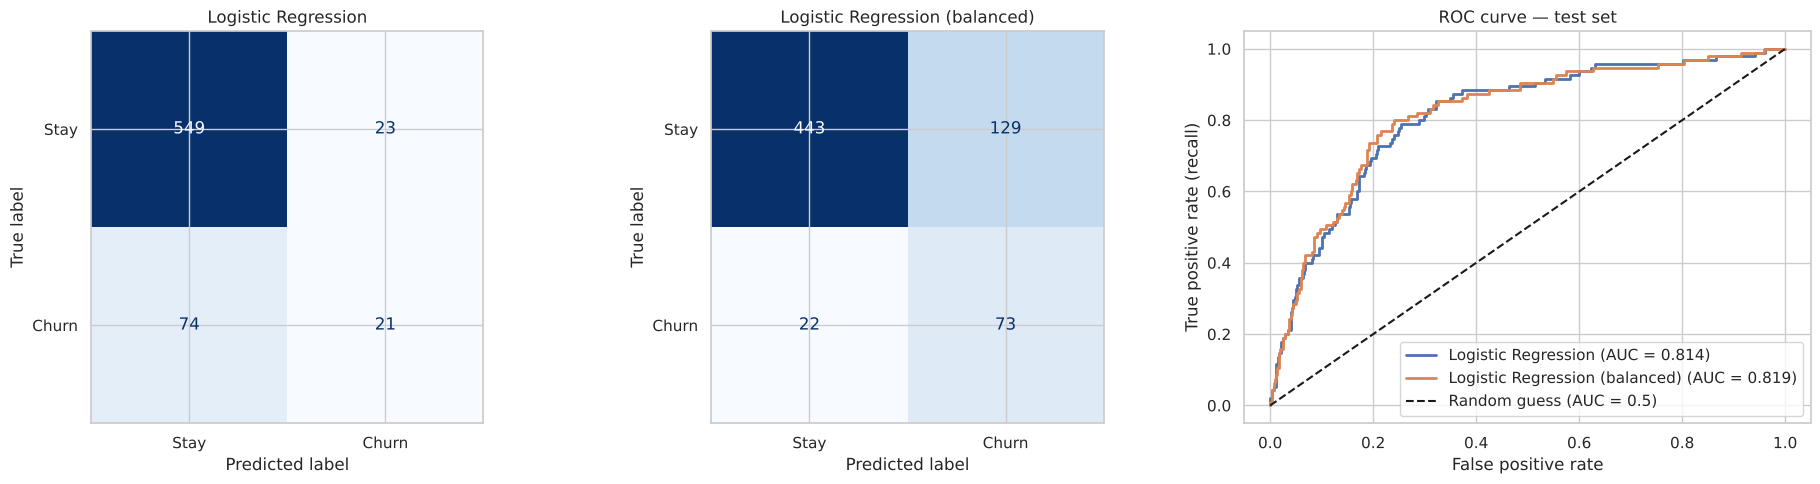

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, pipe) in zip(axes[:2], fitted.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pipe.predict(X_test), display_labels=["Stay", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[2].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate (recall)")
axes[2].set_title("ROC curve — test set"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "confusion_roc.png", dpi=120); plt.show()

### Choosing the decision threshold
The default threshold is 0.5. Moving it trades precision for recall — useful when missing a churner is costlier than
contacting a loyal customer.

In [10]:
proba = fitted["Logistic Regression"].predict_proba(X_test)[:, 1]
thr_rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    thr_rows.append({"threshold": t, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                     "recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
pd.DataFrame(thr_rows).round(3)

,threshold,accuracy,precision,recall,F1
0,0.2,0.795,0.365,0.600,0.454
1,0.3,0.834,0.420,0.442,0.431
2,0.4,0.859,0.508,0.347,0.412
3,0.5,0.855,0.477,0.221,0.302
4,0.6,0.862,0.560,0.147,0.233


## 6. Interpreting coefficients and odds ratios
For logistic regression: `log(odds of churn) = b0 + b1·x1 + …`
* **Coefficient** = change in the *log-odds* of churn for a one-unit increase in the feature.
* **Odds ratio = e^coefficient** = how many times the odds of churning are multiplied.
  OR > 1 → raises churn risk; OR < 1 → lowers it.

Numeric features are standardized, so for them "one unit" = **one standard deviation**. For binary features one unit = having the plan.

In [11]:
pipe = fitted["Logistic Regression"]
names = pipe.named_steps["prep"].get_feature_names_out()
coef = pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": names, "coefficient": coef, "odds_ratio": np.exp(coef)})
coef_df["feature"] = coef_df["feature"].str.replace(r"^(num|bin|cat)__", "", regex=True)
core = coef_df[~coef_df["feature"].str.startswith("State_")].sort_values("coefficient", ascending=False)
print(f"Intercept: {pipe.named_steps['clf'].intercept_[0]:.3f}")
core.round(3).reset_index(drop=True)

Intercept: -2.202


,feature,coefficient,odds_ratio
0,International plan,2.151,8.597
1,Total day minutes,0.697,2.008
2,Customer service calls,0.692,1.997
3,Total eve minutes,0.301,1.351
4,Total intl minutes,0.266,1.305
5,Number vmail messages,0.255,1.291
6,Total night minutes,0.149,1.161
7,Total day calls,0.071,1.073
8,Account length,0.052,1.054
9,Total night calls,0.033,1.033


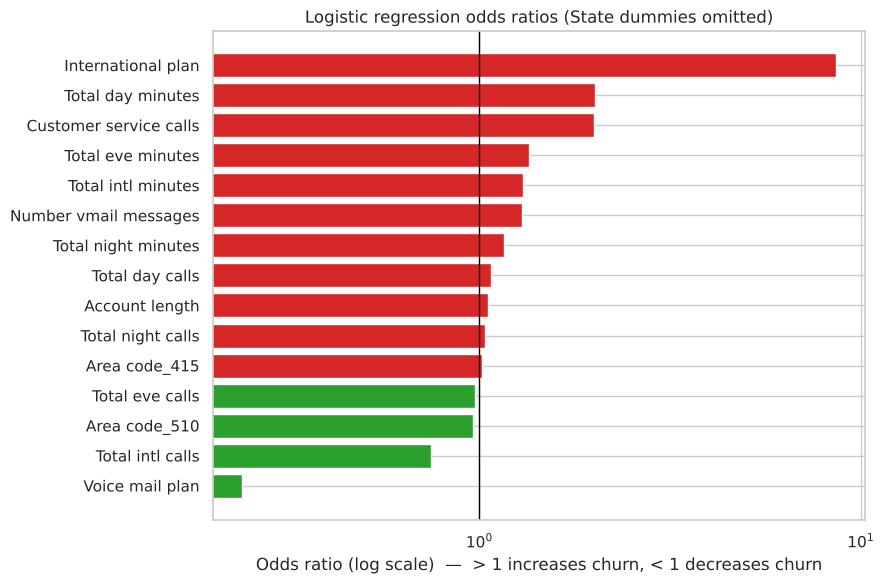

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = core.sort_values("odds_ratio")
ax.barh(plot_df["feature"], plot_df["odds_ratio"],
        color=["#d62728" if v > 1 else "#2ca02c" for v in plot_df["odds_ratio"]])
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (log scale)  —  > 1 increases churn, < 1 decreases churn")
ax.set_title("Logistic regression odds ratios (State dummies omitted)")
plt.tight_layout(); plt.savefig(IMG / "odds_ratios.png", dpi=120); plt.show()

In [13]:
state = coef_df[coef_df["feature"].str.startswith("State_")].sort_values("odds_ratio")
print("States with the highest / lowest churn odds (relative to the reference state AK):")
pd.concat([state.tail(3), state.head(3)]).round(3)

States with the highest / lowest churn odds (relative to the reference state AK):


,feature,coefficient,odds_ratio
38,State_MT,0.813,2.255
52,State_SC,0.923,2.517
55,State_TX,1.041,2.832
51,State_RI,-1.130,0.323
57,State_VA,-0.998,0.369
23,State_HI,-0.921,0.398


## Conclusions
**Performance (test set, 667 customers)**
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.855 | 0.477 | 0.221 | 0.302 | 0.814 |
| Logistic Regression (balanced) | 0.774 | 0.361 | **0.768** | **0.492** | **0.819** |

* Both models rank customers well (**ROC-AUC ≈ 0.81–0.82**, cross-validated AUC ≈ 0.80, so the result is stable).
* The standard model has the higher accuracy but only catches **22 %** of churners — barely better than the 85 % "nobody churns"
  baseline. With `class_weight="balanced"` the model catches **77 %** of churners, at the cost of more false alarms.
  For a retention campaign (where losing a customer costs more than a discount offer) the **balanced model is the better choice**.
  The threshold table shows the same trade-off can also be tuned by moving the decision threshold.

**What drives churn (odds ratios)**
* **International plan** — OR ≈ **8.6**: customers with an international plan have ~8.6× the odds of churning.
* **Total day minutes** — OR ≈ 2.0 per +1 SD (~54 min): heavy daytime users are much more likely to leave (they pay the most).
* **Customer service calls** — OR ≈ 2.0 per +1 SD (~1.3 calls): every complaint call sharply increases churn risk.
* **Voice mail plan** — OR ≈ **0.24**: having voice mail cuts the odds of churn by ~76 % (a sign of an engaged customer).
* Number of calls, account length and area code have odds ratios close to 1 → almost no effect.

**Limitation:** logistic regression assumes a linear relationship with the log-odds. Churn rises *sharply* after the 4th
customer-service call (see EDA), which a straight line cannot capture — tree-based models (Level 3 · Random Forest) handle this better.